# 09 · Diffusion Transformers and Flow Matching: The Architecture of Modern Image Generators

## Overview

| # | Notebook | Idea | What it fixes | What it leaves open |
|---|---|---|---|---|
| 01 | Pretraining | Next-token prediction on raw text | Knowledge: the model *can* add | Doesn't follow instructions |
| 02 | SFT + LoRA | Imitate demonstrations | Follows the chat format | Copies demonstrators' mistakes; forgets |
| 03 | Reward model + PPO | Learn a reward from preferences, optimise it | Can go beyond imitation | Reward hacking; four models; fragile |
| 04 | DPO family | Optimise preferences directly, no RL loop | Simple and stable | Offline: only re-weights existing behaviour |
| 05 | GRPO / RLVR | Online RL against a verifier | Verifiable gains, no value network | Sharpens, rarely expands; needs a capable start |
| 06 | Diffusion | Learn to denoise | Stable, high-quality generation | Matches data, not *goals*; slow sampling |
| 07 | Diffusion post-training | Fine-tune and reward-align a denoiser | Steer generation to a goal | Reward hacking again; still slow |
| 08 | Distillation | Few-step students | 10-100x faster sampling | Small denoisers don't scale |
| **09** | **Diffusion transformers** | **Tokens + adaLN + flow matching** | **Scalable, flexible conditioning** | **Needs post-training too** |
| 10 | Capstone | GRPO and DPO on a DiT; diffusion LMs | Unifies both threads | → the research frontier |

Every denoiser so far was an MLP over a flat 64-number vector, with the condition entering as one label embedding.
Modern image generators look different on both counts:

* **Architecture.** The U-Net of early diffusion models gave way to the **Diffusion Transformer (DiT)** ([Peebles & Xie, 2022](https://arxiv.org/abs/2212.09748); see also U-ViT, [Bao et al., 2022](https://arxiv.org/abs/2209.12152)). The image is cut into patches, as in ViT ([Dosovitskiy et al., 2020](https://arxiv.org/abs/2010.11929)), each patch becomes a token, and a plain transformer denoises the token sequence. Time and class enter through **adaptive LayerNorm** (adaLN), a descendant of FiLM ([Perez et al., 2017](https://arxiv.org/abs/1709.07871)).
* **Objective.** DDPM noise schedules gave way to **flow matching / rectified flow** ([Lipman et al., 2022](https://arxiv.org/abs/2210.02747), [Liu et al., 2022](https://arxiv.org/abs/2209.03003), [Albergo et al., 2023](https://arxiv.org/abs/2303.08797)), which notebook 08 introduced. SiT ([Ma et al., 2024](https://arxiv.org/abs/2401.08740)) showed the two choices combine cleanly.
* **Conditioning.** Stable Diffusion 3 ([Esser et al., 2024](https://arxiv.org/abs/2403.03206)) puts text tokens and image tokens in one sequence with **joint attention** (MM-DiT), samples training times from a logit-normal distribution, and trains with rectified flow. PixArt-α ([Chen et al., 2023](https://arxiv.org/abs/2310.00426)) and FLUX ([Labs et al., 2025](https://arxiv.org/abs/2506.15742)) are DiTs in the same family.

This notebook builds a small version of each piece. It also measures where a transformer does **not** help at
our scale.

## Learning objectives

1. Patchify an image into tokens and build a DiT block with adaLN-Zero conditioning.
2. Train DiT and MLP denoisers with flow matching on equal terms, and read the comparison honestly.
3. Build a text-conditioned DiT with joint text–image attention, and test **compositional generalisation** on a caption it never saw.
4. Explain why a DiT is the natural meeting point of the two threads of this series.

**Runtime:** about 12 minutes on a laptop CPU (the transformers dominate).

In [1]:
import sys, time, os, inspect
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
sys.path.insert(0, ".")
from ptlib import images, metrics, set_seed, CKPT_DIR
from ptlib import diffusion as dfx, dit
torch.set_num_threads(min(8, torch.get_num_threads()))
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 20)
Xtr, ytr, Xte, yte = images.load_digits_tensor()
judge = images.get_judge(); knn = images.PixelKNN()
sc = metrics.ImageScorecard(judge, Xtr, Xte, yte); sc.real_baseline()

{'model': 'real data',
 'fd': 3.3215583525031938,
 'precision': 0.9693593314763231,
 'coverage': 0.9693593314763231,
 'nn_ratio': 1.0199902057647705,
 'nfe': 0,
 'judge_acc': 0.9805014133453369}

## 1. From pixels to tokens

A DiT never sees the image as one vector. It cuts the image into $p \times p$ patches, linearly embeds each one, and
adds a learned position embedding. With $p = 2$, our 8×8 digit becomes a sequence of **16 tokens**, each describing a 2×2 patch.

image (1, 64) -> tokens (1, 16, 4) | round trip exact: True


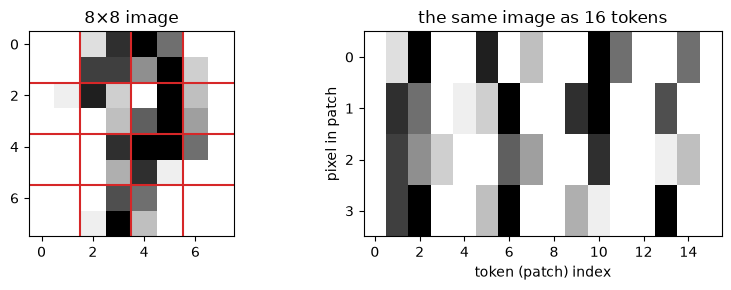

In [2]:
tokens = dit.patchify(Xtr[:1])
print("image (1, 64) -> tokens", tuple(tokens.shape), "| round trip exact:", torch.equal(dit.unpatchify(tokens), Xtr[:1]))
fig, axes = plt.subplots(1, 2, figsize=(8, 3))
axes[0].imshow(Xtr[0].view(8, 8), cmap="gray_r"); axes[0].set_title("8×8 image")
for k in range(1, 4):
    axes[0].axhline(2 * k - 0.5, c="tab:red"); axes[0].axvline(2 * k - 0.5, c="tab:red")
axes[1].imshow(tokens[0].T, cmap="gray_r", aspect="auto"); axes[1].set_xlabel("token (patch) index"); axes[1].set_ylabel("pixel in patch")
axes[1].set_title("the same image as 16 tokens"); fig.tight_layout(); plt.show()

## 2. The DiT block and adaLN-Zero

How does a transformer know the noise level $t$ and the class $c$? DiT computes a conditioning vector
$e = \mathrm{emb}(t) + \mathrm{emb}(c)$ and lets it **modulate every block**. LayerNorm's shift $\beta$ and scale $\gamma$ are predicted from
$e$, and a learned **gate** $g$ scales each residual branch:
$$h \leftarrow h + g_1(e) \odot \mathrm{Attn}\big((1 + \gamma_1(e)) \odot \mathrm{LN}(h) + \beta_1(e)\big), \qquad h \leftarrow h + g_2(e) \odot \mathrm{MLP}(\cdots).$$

The layer that predicts $(\beta, \gamma, g)$ is initialised to **zero**, so every block starts as the identity
("adaLN-Zero"). [Peebles & Xie, 2022](https://arxiv.org/abs/2212.09748) found this the best of the conditioning schemes they compared, which included
cross-attention and in-context tokens. It is the same trick as LoRA's $B = 0$ and ControlNet's zero convolutions:
start exactly where you are and let training open the gate.

In [3]:
print(inspect.getsource(dit.DiTBlock))
m0 = dit.DiT()
with torch.no_grad():
    out = m0(torch.randn(4, 64), torch.full((4,), 500.0), torch.tensor([1, 2, 3, 4]))
print(f"DiT: {sum(p.numel() for p in m0.parameters()):,} parameters; output at initialisation is exactly zero: {bool((out == 0).all())}")

class DiTBlock(nn.Module):
    """h <- h + g1 * Attn(mod(LN(h))) ; h <- h + g2 * MLP(mod(LN(h))), with shift/scale/gate predicted from c."""

    def __init__(self, d, heads):
        super().__init__()
        self.ln1 = nn.LayerNorm(d, elementwise_affine=False)
        self.ln2 = nn.LayerNorm(d, elementwise_affine=False)
        self.attn = nn.MultiheadAttention(d, heads, batch_first=True)
        self.mlp = nn.Sequential(nn.Linear(d, 4 * d), nn.GELU(), nn.Linear(4 * d, d))
        self.ada = nn.Sequential(nn.SiLU(), nn.Linear(d, 6 * d))
        nn.init.zeros_(self.ada[1].weight); nn.init.zeros_(self.ada[1].bias)      # adaLN-Zero: block starts as identity

    def forward(self, h, c):
        s1, sc1, g1, s2, sc2, g2 = self.ada(c).chunk(6, -1)
        a = modulate(self.ln1(h), s1, sc1)
        h = h + g1[:, None] * self.attn(a, a, a, need_weights=False)[0]
        return h + g2[:, None] * self.mlp(modulate(self.ln2(h), s2, sc2))

DiT: 1,257,988 parameters; output at initialisation i

## 3. Flow matching with logit-normal timesteps

The objective is notebook 08's rectified flow: $x_s = (1-s)\,x + s\,z$, regress $u = z - x$. One change from SD3
([Esser et al., 2024](https://arxiv.org/abs/2403.03206)): the training time $s$ is drawn from a **logit-normal** distribution, $s = \sigma(n)$ with $n \sim \mathcal{N}(0, 1)$. This
concentrates training on intermediate noise levels, where the velocity is hardest to predict. At the two ends the
answer is nearly trivial, roughly "point at the data mean" or "point at the noise".

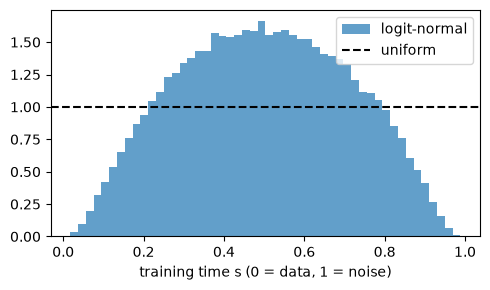

In [4]:
s = torch.sigmoid(torch.randn(100000))
fig, ax = plt.subplots(figsize=(5, 3)); ax.hist(s.numpy(), bins=50, density=True, alpha=0.7, label="logit-normal")
ax.axhline(1, c="k", ls="--", label="uniform"); ax.set_xlabel("training time s (0 = data, 1 = noise)"); ax.legend(); fig.tight_layout(); plt.show()

## 4. DiT vs MLP on equal terms

Both denoisers get the same objective, timestep distribution, optimiser, batch size (128) and number of steps (4,000).
The only difference is the architecture.

step   2000  loss 0.4693  (30s)
step   4000  loss 0.3255  (61s)
MLP denoiser: 1,452,096 parameters, 63s
step   2000  loss 0.4493  (144s)
step   4000  loss 0.3250  (291s)
DiT: 1,257,988 parameters, 291s


,arch,steps,w,fd,precision,coverage,judge_acc
0,MLP denoiser,4,0.0,10.554,0.981,0.919,0.994
1,MLP denoiser,4,1.0,6.078,0.992,0.905,1.000
2,MLP denoiser,20,0.0,7.797,0.969,0.936,0.989
3,MLP denoiser,20,1.0,4.033,0.983,0.939,1.000
4,DiT,4,0.0,9.250,0.975,0.928,0.994
5,DiT,4,1.0,5.599,0.994,0.903,1.000
6,DiT,20,0.0,4.127,0.953,0.933,0.986
7,DiT,20,1.0,4.167,0.972,0.903,0.997


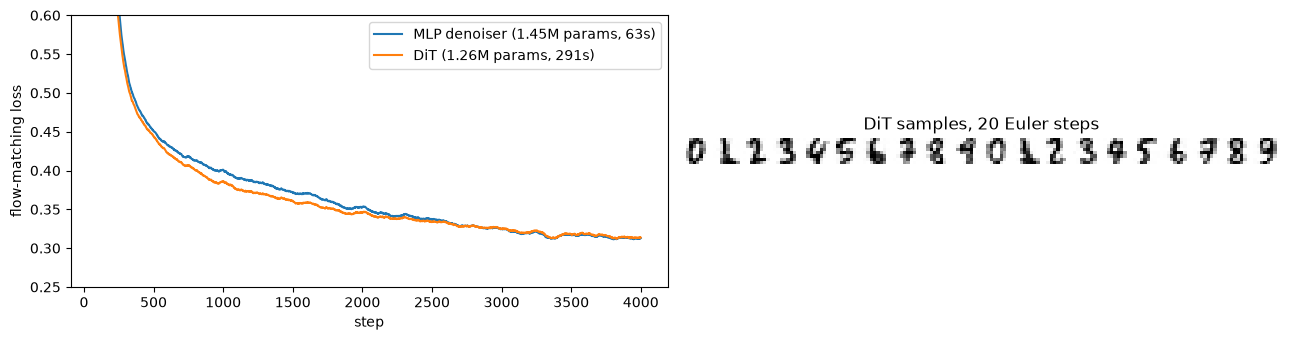

In [5]:
arch = {}
for name, net in [("MLP denoiser", dfx.MLPDenoiser()), ("DiT", dit.DiT())]:
    t0 = time.time()
    ema, loss = dfx.train_flow(net, Xtr, ytr, steps=4000, batch=128, t_sampling="logit_normal", log_every=2000)
    arch[name] = dict(model=ema, loss=loss, seconds=time.time() - t0, params=sum(p.numel() for p in net.parameters()))
    print(f"{name}: {arch[name]['params']:,} parameters, {arch[name]['seconds']:.0f}s")
torch.save(arch["DiT"]["model"].state_dict(), os.path.join(CKPT_DIR, "dit_flow.pt"))            # used by notebook 10

rows = []
for name, a in arch.items():
    for steps in [4, 20]:
        for w in [0.0, 1.0]:
            set_seed(0)
            r = sc.evaluate(dfx.sample_flow(a["model"], yte, steps, w=w), f"{name}, {steps} steps, w={w:g}", labels=yte, nfe=steps * (2 if w else 1))
            rows.append(dict(arch=name, steps=steps, w=w, **{k: r[k] for k in ["fd", "precision", "coverage", "judge_acc"]}))
display(pd.DataFrame(rows).round(3))
fig, axes = plt.subplots(1, 2, figsize=(13, 3.5))
for name, a in arch.items():
    axes[0].plot(pd.Series(a["loss"]).rolling(100).mean(), label=f"{name} ({a['params'] / 1e6:.2f}M params, {a['seconds']:.0f}s)")
axes[0].set_ylim(0.25, 0.6); axes[0].set_xlabel("step"); axes[0].set_ylabel("flow-matching loss"); axes[0].legend()
set_seed(0); images.show_grid(dfx.sample_flow(arch["DiT"]["model"], torch.arange(10).repeat(2), 20), nrow=20, ax=axes[1], title="DiT samples, 20 Euler steps")
fig.tight_layout(); plt.show()

**Reading the comparison honestly.** The two architectures reach the same training loss. Sample quality is mixed.
In this run the DiT has the lower FD without guidance at 20 steps, while the two are about equal at 4 steps and with
guidance. In development runs with other random seeds the ordering of these FD values flipped, so differences of this
size should not be read as an architectural win. What is not in doubt is the cost: the DiT takes several times more
wall-clock time for the same number of steps. On 64-pixel images that is the expected outcome. A flat MLP sees every pixel
at once and is cheap, while a transformer's advantages show up with **scale** and **structure**:

* [Peebles & Xie, 2022](https://arxiv.org/abs/2212.09748) found DiT quality improves predictably with compute (Gflops), and the architecture transfers unchanged from 256² to 512² images and to latent spaces. An MLP over a flat vector has no comparable scaling path.
* Tokens make **conditioning** flexible. Anything that can be tokenised (text, other images, layouts) can join the sequence. That is what the next section tests.

## 5. Conditioning on text with joint attention

Class labels are a closed vocabulary. Text prompts are open-ended and compositional: "a **bold** seven" combines a
style and a content word. MM-DiT ([Esser et al., 2024](https://arxiv.org/abs/2403.03206)) handles text by appending the caption's tokens to the image tokens.
Each modality has its own weights, but a single attention operation runs over the concatenated sequence, so image
tokens can read the caption and caption tokens can read the image. Here the caption is a sequence of characters,
and its pooled embedding also feeds adaLN.

**A compositional test.** We train on captions like `"three"` (normal digits) and `"bold three"` (bold digits) for
every class, **except that bold sevens are left out**. The model has seen "seven" and has seen "bold", but never
together. Can it generate a bold seven?

In [6]:
print(inspect.getsource(dit.JointBlock.forward))
Xb = images.bold(Xtr)
keep = ytr != 7                                                    # no bold sevens in training
Xc = torch.cat([Xtr, Xb[keep]])
captions = [dit.WORDS[int(c)] for c in ytr] + ["bold " + dit.WORDS[int(c)] for c in ytr[keep]]
cap_ids = dit.encode_captions(captions)
print(f"{len(captions)} captioned images; e.g. {captions[0]!r}, {captions[-1]!r}; 'bold seven' in training: {'bold seven' in captions}")
t0 = time.time()
text_dit, _ = dfx.train_flow(dit.TextDiT(), Xc, cap_ids, steps=3000, batch=128, t_sampling="logit_normal", log_every=1000)
print(f"text-conditioned DiT: {sum(p.numel() for p in text_dit.parameters()):,} parameters, {time.time() - t0:.0f}s")
torch.save(text_dit.state_dict(), os.path.join(CKPT_DIR, "text_dit.pt"))

    def forward(self, ht, hi, c, text_mask):
        B, Lt, D = ht.shape
        mt, mi = self.ada["t"](c).chunk(6, -1), self.ada["i"](c).chunk(6, -1)
        qt, kt, vt = self.qkv["t"](modulate(self.ln["t1"](ht), mt[0], mt[1])).chunk(3, -1)
        qi, ki, vi = self.qkv["i"](modulate(self.ln["i1"](hi), mi[0], mi[1])).chunk(3, -1)
        q, k, v = (torch.cat(z, 1).view(B, -1, self.heads, D // self.heads).transpose(1, 2) for z in [(qt, qi), (kt, ki), (vt, vi)])
        keymask = torch.cat([text_mask, torch.ones(B, hi.shape[1], dtype=torch.bool)], 1)[:, None, None, :]
        a = F.scaled_dot_product_attention(q, k, v, attn_mask=keymask).transpose(1, 2).reshape(B, -1, D)
        at, ai = a[:, :Lt], a[:, Lt:]
        ht = ht + mt[2][:, None] * self.proj["t"](at)
        hi = hi + mi[2][:, None] * self.proj["i"](ai)
        ht = ht + mt[5][:, None] * self.mlp["t"](modulate(self.ln["t2"](ht), mt[3], mt[4]))
        hi = hi + mi[5][:, None] * self.mlp["i"](modulate(self.ln["i2"](hi), mi[3],

,prompt,seen_in_training,ink,judge_acc,knn_acc
0,seven,True,0.300,1.000,1.000
1,bold seven,False,0.616,0.000,0.000
2,three,True,0.294,1.000,1.000
3,bold three,True,0.714,0.780,0.990
4,one,True,0.291,1.000,1.000
5,bold one,True,0.614,0.985,0.990
6,"(real bold sevens, for reference)",False,0.686,0.969,0.969


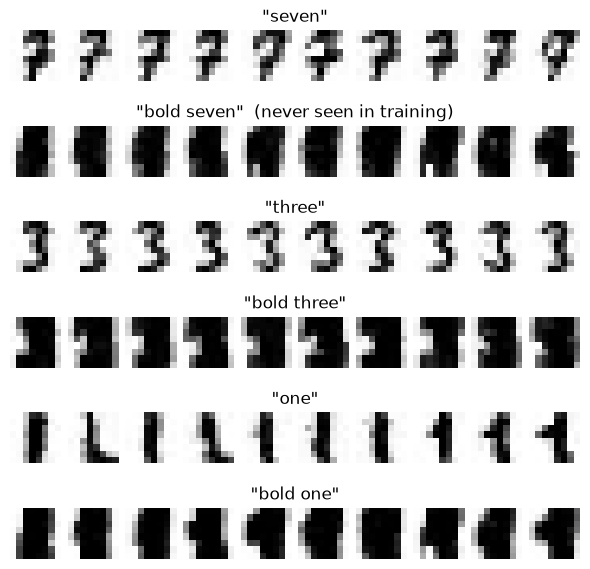

In [7]:
prompts = ["seven", "bold seven", "three", "bold three", "one", "bold one"]
rows, grids = [], {}
for p in prompts:
    set_seed(0)
    s = dfx.sample_flow(text_dit, dit.encode_captions([p] * 200), 20, w=1.0)
    target = torch.full((200,), dit.WORDS.index(p.split()[-1]))
    rows.append(dict(prompt=p, seen_in_training=p in captions, ink=dfx.ink(s).mean().item(),
                     judge_acc=(judge(s).argmax(1) == target).float().mean().item(), knn_acc=knn.accuracy(s, target)))
    grids[p] = s[:10]
rows.append(dict(prompt="(real bold sevens, for reference)", seen_in_training=False, ink=dfx.ink(images.bold(Xte[yte == 7])).mean().item(),
                 judge_acc=(judge(images.bold(Xte[yte == 7])).argmax(1) == 7).float().mean().item(),
                 knn_acc=knn.accuracy(images.bold(Xte[yte == 7]), yte[yte == 7])))
comp = pd.DataFrame(rows); display(comp.round(3))
fig, axes = plt.subplots(len(prompts), 1, figsize=(6, 1.0 * len(prompts)))
for ax, p in zip(axes, prompts):
    images.show_grid(grids[p], nrow=10, ax=ax, title=f'"{p}"' + ("" if p in captions else "  (never seen in training)"))
fig.tight_layout(); plt.show()

**What the compositional test shows.** The model composed **half** of the prompt. "Bold seven" samples are as
inky as the bold digits it was trained on, so the word "bold" was applied. But neither classifier reads them as
sevens. Look at the grid: the model drew bold versions of digits it *has* seen in bold. Faced with an unseen
combination, it fell back to the nearest familiar caption instead of composing "bold" with "seven". Guidance
does not fix it (Challenge Problem 2).

Failures like this are common in real text-to-image models too: counting, attribute binding and unusual
combinations are exactly what compositional benchmarks measure. One response is more and more varied training
data. The other is post-training, which notebook 10 tries.

## 6. Where the two threads meet

Look at what the text-conditioned DiT is: a **transformer** over a sequence of tokens, some of them text, trained by
regression and sampled iteratively. Notebooks 01-05 used a transformer over text tokens trained by next-token
prediction. The architectures are now almost the same, and so are the post-training problems. A pretrained DiT
matches its data, not what users want. Notebook 10 applies GRPO and DPO, the methods from the language thread, to a
DiT. It then goes one step further: a diffusion model that generates **text**.

## 7. Scorecard

In [8]:
t = sc.table().reset_index(); t["family"] = "image"
metrics.append_rows(t[t.model != "real data"].to_dict("records"), "09_dit")
display(metrics.load_scorecard().query("notebook == '09_dit'")[["model", "fd", "precision", "coverage", "judge_acc", "nfe"]].round(3))

,model,fd,precision,coverage,judge_acc,nfe
48,"MLP denoiser, 4 steps, w=0",10.554,0.981,0.919,0.994,4.0
49,"MLP denoiser, 4 steps, w=1",6.078,0.992,0.905,1.000,8.0
50,"MLP denoiser, 20 steps, w=0",7.797,0.969,0.936,0.989,20.0
51,"MLP denoiser, 20 steps, w=1",4.033,0.983,0.939,1.000,40.0
52,"DiT, 4 steps, w=0",9.250,0.975,0.928,0.994,4.0
53,"DiT, 4 steps, w=1",5.599,0.994,0.903,1.000,8.0
54,"DiT, 20 steps, w=0",4.127,0.953,0.933,0.986,20.0
55,"DiT, 20 steps, w=1",4.167,0.972,0.903,0.997,40.0


## Challenge Problem 1: Uniform vs logit-normal timesteps

Train two MLP flow models for 4,000 steps, one with uniform $s$ and one with logit-normal $s$, and compare FD at 4 and 20 Euler steps. [Esser et al., 2024](https://arxiv.org/abs/2403.03206)
found logit-normal sampling clearly better for large models. Does the choice matter for a tiny model on 8×8 digits?

In [9]:
# Start your code here

### Challenge Problem 1 Solution

In [10]:
for ts in ["uniform", "logit_normal"]:
    m, _ = dfx.train_flow(dfx.MLPDenoiser(), Xtr, ytr, steps=4000, batch=128, t_sampling=ts, log_every=0)
    out = []
    for n in [4, 20]:
        set_seed(0); out.append(sc.evaluate(dfx.sample_flow(m, yte, n), f"MLP flow, {ts}, {n} steps", labels=yte)["fd"])
    print(f"{ts:13s} FD at 4 steps {out[0]:.2f}, at 20 steps {out[1]:.2f}")

uniform       FD at 4 steps 13.87, at 20 steps 8.27
logit_normal  FD at 4 steps 11.41, at 20 steps 8.39


## Challenge Problem 2: Guidance for a compositional prompt

Sample "bold seven" from the text-conditioned DiT with guidance $w \in \{0, 1, 3, 6\}$ and report ink and kNN accuracy. Does stronger guidance help the model
compose an unseen combination, or does it trade away recognisability as in notebook 06?

In [11]:
# Start your code here

### Challenge Problem 2 Solution

In [12]:
ids = dit.encode_captions(["bold seven"] * 200); target = torch.full((200,), 7)
for w in [0, 1, 3, 6]:
    set_seed(0); s = dfx.sample_flow(text_dit, ids, 20, w=w)
    print(f"w={w}: ink {dfx.ink(s).mean():.3f}  kNN acc {knn.accuracy(s, target):.3f}  judge acc {(judge(s).argmax(1) == 7).float().mean():.3f}")

w=0: ink 0.622  kNN acc 0.005  judge acc 0.010
w=1: ink 0.616  kNN acc 0.000  judge acc 0.000
w=3: ink 0.599  kNN acc 0.000  judge acc 0.000
w=6: ink 0.594  kNN acc 0.000  judge acc 0.000


## Final summary

* A **DiT** treats an image as a sequence of patch tokens and conditions every block through adaLN-Zero. Combined with **flow matching** and logit-normal timesteps, this is the recipe of SD3, FLUX and PixArt.
* On 8×8 digits, a DiT is no better than an MLP and costs several times more compute. Its advantages are scaling and flexible conditioning, not small-data efficiency.
* **Joint text–image attention** lets a caption steer generation token by token, and supports composing words the model never saw together.
* A DiT is a transformer over tokens, like the language models of notebooks 01-05. Notebook 10 post-trains it with their methods.

## References

* William Peebles, Saining Xie (2022). **Scalable Diffusion Models with Transformers**. arXiv:2212.09748. [arxiv.org/abs/2212.09748](https://arxiv.org/abs/2212.09748)
* Fan Bao, Shen Nie, Kaiwen Xue et al. (2022). **All are Worth Words: A ViT Backbone for Diffusion Models**. arXiv:2209.12152. [arxiv.org/abs/2209.12152](https://arxiv.org/abs/2209.12152)
* Alexey Dosovitskiy, Lucas Beyer, Alexander Kolesnikov et al. (2020). **An Image is Worth 16x16 Words: Transformers for Image Recognition at Scale**. arXiv:2010.11929. [arxiv.org/abs/2010.11929](https://arxiv.org/abs/2010.11929)
* Ethan Perez, Florian Strub, Harm de Vries et al. (2017). **FiLM: Visual Reasoning with a General Conditioning Layer**. arXiv:1709.07871. [arxiv.org/abs/1709.07871](https://arxiv.org/abs/1709.07871)
* Yaron Lipman, Ricky T. Q. Chen, Heli Ben-Hamu et al. (2022). **Flow Matching for Generative Modeling**. arXiv:2210.02747. [arxiv.org/abs/2210.02747](https://arxiv.org/abs/2210.02747)
* Xingchao Liu, Chengyue Gong, Qiang Liu (2022). **Flow Straight and Fast: Learning to Generate and Transfer Data with Rectified Flow**. arXiv:2209.03003. [arxiv.org/abs/2209.03003](https://arxiv.org/abs/2209.03003)
* Michael S. Albergo, Nicholas M. Boffi, Eric Vanden-Eijnden (2023). **Stochastic Interpolants: A Unifying Framework for Flows and Diffusions**. arXiv:2303.08797. [arxiv.org/abs/2303.08797](https://arxiv.org/abs/2303.08797)
* Nanye Ma, Mark Goldstein, Michael S. Albergo et al. (2024). **SiT: Exploring Flow and Diffusion-based Generative Models with Scalable Interpolant Transformers**. arXiv:2401.08740. [arxiv.org/abs/2401.08740](https://arxiv.org/abs/2401.08740)
* Patrick Esser, Sumith Kulal, Andreas Blattmann et al. (2024). **Scaling Rectified Flow Transformers for High-Resolution Image Synthesis**. arXiv:2403.03206. [arxiv.org/abs/2403.03206](https://arxiv.org/abs/2403.03206)
* Junsong Chen, Jincheng Yu, Chongjian Ge et al. (2023). **PixArt-$α$: Fast Training of Diffusion Transformer for Photorealistic Text-to-Image Synthesis**. arXiv:2310.00426. [arxiv.org/abs/2310.00426](https://arxiv.org/abs/2310.00426)
* Black Forest Labs, Stephen Batifol, Andreas Blattmann et al. (2025). **FLUX.1 Kontext: Flow Matching for In-Context Image Generation and Editing in Latent Space**. arXiv:2506.15742. [arxiv.org/abs/2506.15742](https://arxiv.org/abs/2506.15742)

The full, verified list for the series is in [`research_papers/README.md`](research_papers/README.md).